In [1]:
# Everything in this file.

<!-- HARUT_PART4_BEGIN -->
# Part 12.2 — Government popularity and public opinion (Person 4)

**Research question:** Was Hong Kong's Scheme $6,000 followed by a sustained improvement in satisfaction with the HKSAR Government?

This section follows CORE Econ, *Doing Economics*, Project 12, **Part 12.2 (Working in Python)**, particularly Questions 1–3 and Python walk-throughs 12.5–12.6. It uses survey **end dates**, the original net-satisfaction definition, and two related social indicators: *degree of prosperity* and *degree of equality*.

**Data files (HKU POP / PORI):**
- `People’s Satisfaction with the HKSAR Government.xlsx`
- `Appraisal of Degree of Prosperity.xlsx`
- `Appraisal of Degree of Equality.xlsx`

For a reproducible final group submission, put all three Excel files under `data/` in this repository. During development, this section also searches a sibling checkout of the original `Macroeconomics-hong-kong-cash-handout/data` folder.

CORE instructions: https://books.core-econ.org/doing-economics/book/text/12-06.html#part-122-government-popularity

PORI historical indicator archive: https://a2024.pori.hk/pop-poll/social-indicators.html?lang=en


In [2]:
# Part 12.2 — imports and source-file discovery (all variables prefixed p4_)
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

p4_files = {
    "satisfaction": "People’s Satisfaction with the HKSAR Government.xlsx",
    "prosperity": "Appraisal of Degree of Prosperity.xlsx",
    "equality": "Appraisal of Degree of Equality.xlsx",
}

# We can run from the repo root or notebooks/; the old repo may be a sibling folder.
p4_cwd = Path.cwd()
p4_search_dirs = []
for p4_parent in [p4_cwd, p4_cwd.parent, p4_cwd.parent.parent]:
    p4_search_dirs.extend([
        p4_parent / "data",
        p4_parent / "Macroeconomics-hong-kong-cash-handout" / "data",
    ])
p4_data_dir = next(
    (d for d in p4_search_dirs if all((d / name).is_file() for name in p4_files.values())),
    None,
)
if p4_data_dir is None:
    raise FileNotFoundError(
        "Part 4 needs three HKU POP Excel files in macro_final/data/. "
        "Copy them from the earlier Macroeconomics-hong-kong-cash-handout/data folder "
        "and rerun this cell. Required: " + ", ".join(p4_files.values())
    )
print("Part 4 data folder:", p4_data_dir.resolve())


Part 4 data folder: C:\Users\PrestamoTGC\macro_final\data


In [3]:
# CORE walk-through 12.5: header is row 2, so use skiprows=1.
def p4_load_survey(filename, value_columns, respondents_column):
    raw = pd.read_excel(p4_data_dir / filename, skiprows=1)
    rename = {
        "調查開始日期Survey Start Date": "start_date",
        "調查結束日期Survey End Date": "survey_date",
        "樣本數目Sample size": "sample_size",
        "回應比率Response rate": "response_rate",
        "回應比率Response Rate": "response_rate",
        respondents_column: "respondents",
        **value_columns,
    }
    data = raw.rename(columns=rename).copy()
    required = ["survey_date", "sample_size", "response_rate", "respondents", *value_columns.values()]
    absent = [c for c in required if c not in data.columns]
    if absent:
        raise ValueError(f"Unexpected column layout in {filename}: {absent}")
    data["survey_date"] = pd.to_datetime(data["survey_date"], errors="coerce")
    if "start_date" in data.columns:
        data["start_date"] = pd.to_datetime(data["start_date"], errors="coerce")
    for col in required:
        if col != "survey_date":
            data[col] = pd.to_numeric(data[col], errors="coerce")
    # Keep valid survey observations; do not drop rows just because the Remark field is empty.
    data = data.dropna(subset=["survey_date", *value_columns.values()])
    data = data.sort_values("survey_date").reset_index(drop=True)
    return data

p4_satisfaction = p4_load_survey(
    p4_files["satisfaction"],
    {"滿意Satisfied": "satisfied", "唔滿意Dissatisfied": "dissatisfied",
     "淨值Netvalue": "reported_net", "平均量值Mean value": "mean_satisfaction"},
    "基數Base",
)
p4_prosperity = p4_load_survey(
    p4_files["prosperity"], {"繁榮Prosperity": "prosperity"},
    "評分人數Number of Raters",
)
p4_equality = p4_load_survey(
    p4_files["equality"], {"平等Equality": "equality"},
    "評分人數Number of Raters",
)

for p4_name, p4_df in [("Government satisfaction", p4_satisfaction),
                       ("Prosperity", p4_prosperity), ("Equality", p4_equality)]:
    print(f"{p4_name}: {len(p4_df)} observations; "
          f"{p4_df.survey_date.min().date()} through {p4_df.survey_date.max().date()}")


Government satisfaction: 406 observations; 1997-07-30 through 2024-11-07
Prosperity: 105 observations; 1997-06-25 through 2024-09-04
Equality: 79 observations; 1997-06-25 through 2024-09-04


### Question 1 — Who might favour or oppose a universal HK$6,000 handout?

**Possible supporters:** adult permanent residents seeking immediate relief from higher living costs; people not covered by the original MPF-based proposal; and the government, if the scheme made surplus redistribution more publicly acceptable.

**Possible opponents:** people favouring long-term public services, anti-poverty measures or housing assistance over a one-off payment; advocates of means-testing who object to paying high-income residents the same amount; and groups excluded by the permanent-resident eligibility rule.

These are plausible incentives, **not survey estimates of support by demographic group**. The policy was a broad cash transfer rather than an income-tested poverty programme.

Policy background: https://www.news.gov.hk/en/categories/health/html/2011/06/20110616_143944.shtml


### Question 2 — Survey methodology and representativeness

The historical HKU Public Opinion Programme used **random telephone surveys conducted by interviewers** and weighted results to population characteristics such as age and sex. Telephone surveys are useful for repeated trend measurements, but do not automatically provide a perfectly representative sample. The survey's *base/number of raters* can be smaller than its overall sample, and response rates do not eliminate nonresponse bias.

Potential limitations:

- Household telephone access and willingness to answer may be related to respondent characteristics.
- Question-specific subsamples yield fewer observations than the survey's headline sample.
- Government satisfaction reflects many political and economic issues, not just Scheme $6,000.
- Historical survey practices changed over time: mobile-phone samples were introduced into HKU POP's regular tracking frame from 2017, which matters when comparing the full 2006–2024 series.
- These are **repeated cross-sectional surveys**, not a randomized evaluation of a policy.

Survey methods and historical details: https://hkupop.pori.hk/english/features/budget/surveymethod.html and https://hkupop.pori.hk/english/release/release1497.html


Maximum difference vs published net value: 0.1 pp


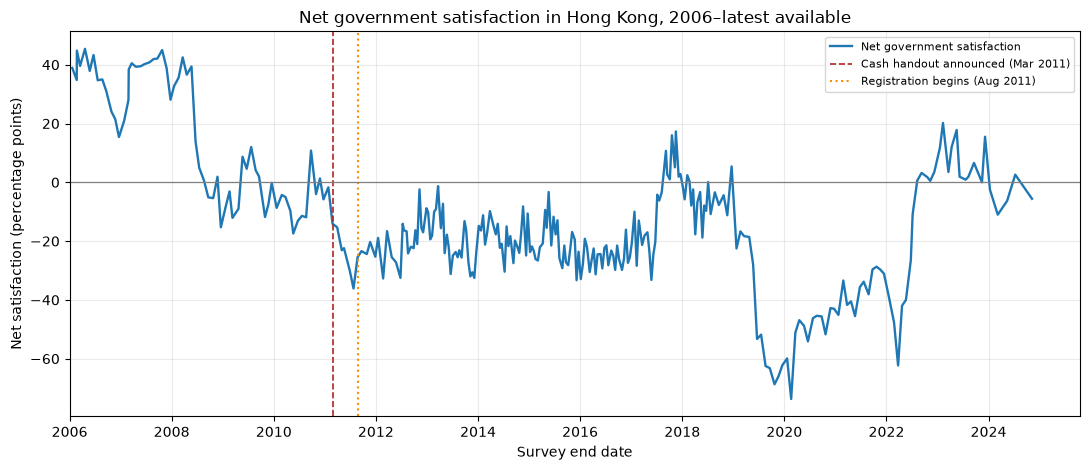

297 observations; latest survey: 2024-11-07


In [4]:
# CORE 12.6: calculate net satisfaction as a percentage-point difference.
p4_satisfaction["net_pp"] = 100 * (
    p4_satisfaction["satisfied"] - p4_satisfaction["dissatisfied"]
)
p4_satisfaction["reported_net_pp"] = 100 * p4_satisfaction["reported_net"]
p4_error = (p4_satisfaction["net_pp"] - p4_satisfaction["reported_net_pp"]).abs()
print("Maximum difference vs published net value:", round(p4_error.max(), 3), "pp")
assert p4_error.max() <= 0.11, "Net satisfaction disagrees with the source data."

p4_survey_data = {
    "Net government satisfaction": (p4_satisfaction, "net_pp", "Percentage points"),
    "Degree of prosperity": (p4_prosperity, "prosperity", "Appraisal (0–10)"),
    "Degree of equality": (p4_equality, "equality", "Appraisal (0–10)"),
}

p4_policy_announcement = pd.Timestamp("2011-03-02")
p4_registration_begins = pd.Timestamp("2011-08-28")

def p4_plot_series(title, df, value_col, y_label):
    series = df.loc[df["survey_date"] >= "2006-01-01"].dropna(subset=[value_col])
    fig, ax = plt.subplots(figsize=(11, 4.8))
    ax.plot(series["survey_date"], series[value_col], linewidth=1.7, label=title)
    ax.axvline(p4_policy_announcement, linestyle="--", color="firebrick",
               linewidth=1.2, label="Cash handout announced (Mar 2011)")
    ax.axvline(p4_registration_begins, linestyle=":", color="darkorange",
               linewidth=1.5, label="Registration begins (Aug 2011)")
    if value_col == "net_pp":
        ax.axhline(0, linewidth=0.9, color="gray")
    else:
        ax.set_ylim(0, 10)
    ax.set_xlim(left=pd.Timestamp("2006-01-01"))
    ax.set_title(title + " in Hong Kong, 2006–latest available")
    ax.set_xlabel("Survey end date")
    ax.set_ylabel(y_label)
    ax.grid(alpha=0.25)
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    plt.show()
    print(f"{len(series)} observations; latest survey: {series.survey_date.max().date()}")

# CORE Question 3(a): net satisfaction, Jan 2006 through latest available.
p4_plot_series("Net government satisfaction", p4_satisfaction, "net_pp", "Net satisfaction (percentage points)")


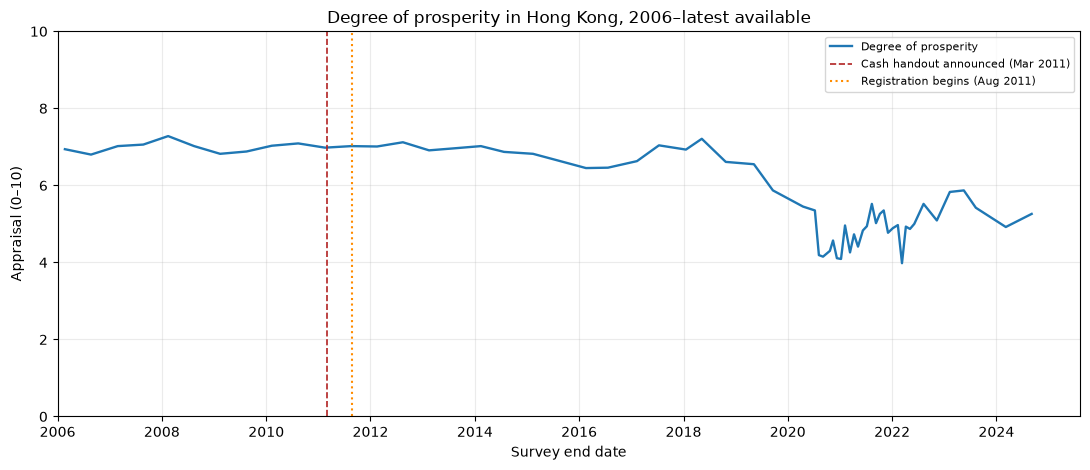

61 observations; latest survey: 2024-09-04


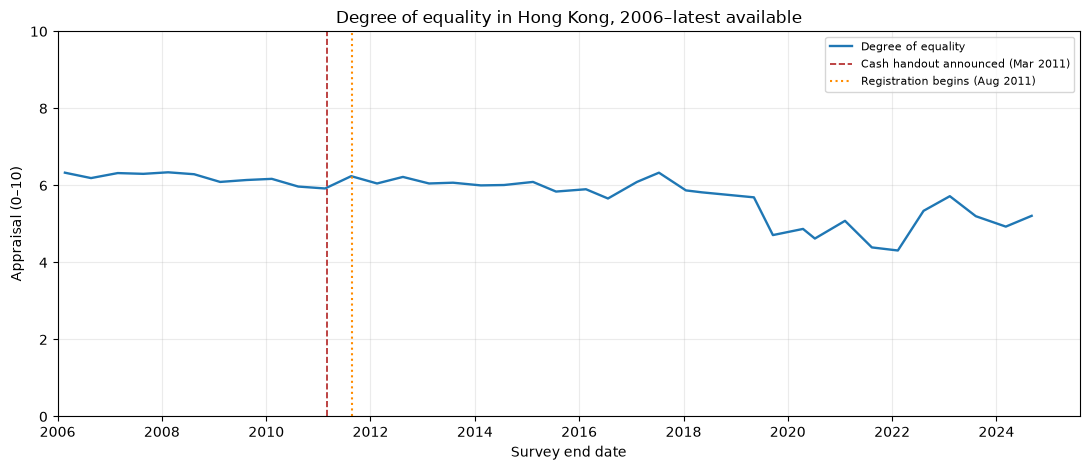

38 observations; latest survey: 2024-09-04


In [5]:
# CORE Question 3(b)–(c): one or two related indicators, separate charts.
p4_plot_series("Degree of prosperity", p4_prosperity, "prosperity", "Appraisal (0–10)")
p4_plot_series("Degree of equality", p4_equality, "equality", "Appraisal (0–10)")


### Question 3 — Interpreting the charts

The three charts deliberately use the **same date window** (January 2006 to each indicator's latest available survey), but government satisfaction is in **percentage points** whereas prosperity and equality are appraisals on a **0–10 scale**. We compare *directions and persistence of changes*, not the levels of the three different scales.

The vertical lines identify the March 2011 policy announcement and August 2011 start of registration. They **do not establish a causal break**. Also, the CORE 2012 Gini simulation is a hypothetical accounting exercise; it should not be confused with the actual timing of registrations and disbursements.

For clarity, the next cell compares two pre-policy years (2009–2010) with two later years (2012–2013), using *equal weight per year's mean* rather than allowing months with more polls to dominate.


In [6]:
# Descriptive before-and-after comparison; 2011 excluded as a transition year.
p4_comparisons = []
for p4_name, (p4_df, p4_col, p4_units) in p4_survey_data.items():
    p4_annual = p4_df.assign(year=p4_df.survey_date.dt.year).groupby("year")[p4_col].mean()
    p4_before = p4_annual.reindex([2009, 2010]).mean()
    p4_after = p4_annual.reindex([2012, 2013]).mean()
    p4_comparisons.append({
        "Indicator": p4_name,
        "2009–2010 mean": p4_before,
        "2012–2013 mean": p4_after,
        "Difference": p4_after - p4_before,
        "Units": p4_units,
    })
p4_comparison = pd.DataFrame(p4_comparisons)
display(p4_comparison.round(3))
print("These are descriptive changes, not estimates of the handout's causal effect.")


,Indicator,2009–2010 mean,2012–2013 mean,Difference,Units
0,Net government satisfaction,-4.162,-19.536,-15.374,Percentage points
1,Degree of prosperity,6.955,7.000,0.045,Appraisal (0–10)
2,Degree of equality,6.092,6.098,0.005,Appraisal (0–10)


These are descriptive changes, not estimates of the handout's causal effect.


In [7]:
# Survey reliability summary for the relevant 2009–2013 period.
p4_survey_summary = []
for p4_name, (p4_df, _p4_col, _p4_units) in p4_survey_data.items():
    p4_window = p4_df.loc[p4_df.survey_date.dt.year.between(2009, 2013)]
    p4_survey_summary.append({
        "Indicator": p4_name,
        "Surveys (2009–13)": len(p4_window),
        "Mean full sample": p4_window.sample_size.mean(),
        "Mean question respondents": p4_window.respondents.mean(),
        "Mean response rate (%)": p4_window.response_rate.mean() * 100,
    })
p4_survey_summary = pd.DataFrame(p4_survey_summary)
display(p4_survey_summary.round(1))


,Indicator,Surveys (2009–13),Mean full sample,Mean question respondents,Mean response rate (%)
0,Net government satisfaction,79,1014.8,726.3,67.2
1,Degree of prosperity,10,1022.1,752.8,66.1
2,Degree of equality,10,1022.1,658.5,66.1


### Linking perceived equality to the Part 12.1 model

CORE's **hypothetical 100-household model** reports Gini coefficients of approximately **0.468760 (2011), 0.451902 (2012 with the assumed HK$6,000 transfer), and 0.469819 (2013)**. These are not observed official Hong Kong Gini statistics; they result from the exercise's assumptions. Compare them with mean survey perceptions, not as if they measured the same thing.

The model treats the handout as an addition to 2012 incomes for instructional purposes. The actual registration programme began in August **2011**, with eligibility/registration arrangements extending into **2012**.

CORE model: https://books.core-econ.org/doing-economics/book/text/12-06.html#part-121-inequality
Official registration announcement: https://www.news.gov.hk/en/categories/health/html/2011/06/20110616_143944.shtml


In [8]:
p4_core_gini = pd.DataFrame({
    "year": [2011, 2012, 2013],
    "CORE modelled Gini": [0.468760, 0.451902, 0.469819],
})
p4_equality_annual = (
    p4_equality.assign(year=p4_equality.survey_date.dt.year)
    .loc[lambda d: d.year.between(2011, 2013)]
    .groupby("year").agg(
        perceived_equality=("equality", "mean"),
        survey_count=("equality", "size")
    ).reset_index()
)
p4_gini_perception = p4_core_gini.merge(p4_equality_annual, on="year", how="left")
display(p4_gini_perception.round(4))


,year,CORE modelled Gini,perceived_equality,survey_count
0,2011,0.4688,6.080,2
1,2012,0.4519,6.135,2
2,2013,0.4698,6.060,2


### Findings, alternative explanations, and limitations

**Interpretation:** The before/after table and three time-series plots should be read together. In our previously completed analysis of these same survey files, net government satisfaction fell rather than showing a sustained post-handout increase, while prosperity and equality perceptions changed much less. The freshly computed tables above are the authoritative values in this notebook.

This means **we cannot claim that Scheme $6,000 produced a lasting popularity gain**. However, it also does **not prove that the scheme caused dissatisfaction**: we have neither a matched control group nor a counterfactual popularity trend. Inflation, housing costs, wider economic conditions, political disputes around the Budget, and changes in political leadership may have contributed to the movements.

**Connection with inequality:** CORE's simplified model shows a lower Gini in its transfer year followed by a reversal in 2013. The accompanying equality appraisals move only slightly, illustrating the distinction between a mechanical redistribution simulation and how society perceives equality.

**Sampling caveats:** The full sample is not the same as the number answering each question. Survey participation, coverage, weighting, and changes in the telephone sampling frame can affect trend comparisons. Don't interpret the 0–10 appraisal scores as percentages.

**Scope note:** CORE Part 12.2's 2018 handout comparison and final policy recommendation are assigned to the group's policy section (Person 3) and should be incorporated there, not duplicated here.

#### Sources
- CORE Econ (Python, Project 12): https://books.core-econ.org/doing-economics/book/text/12-06.html
- PORI social indicators archive: https://a2024.pori.hk/pop-poll/social-indicators.html?lang=en
- HKU POP methods: https://hkupop.pori.hk/english/features/budget/surveymethod.html
- HKU POP changes to mobile sampling (2017): https://hkupop.pori.hk/english/release/release1497.html
- Hong Kong government, cash-handout registration start: https://www.news.gov.hk/en/categories/health/html/2011/06/20110616_143944.shtml
- Kwong (2013), comparative policy study: https://doi.org/10.1177/186810261304200305

<!-- HARUT_PART4_END -->
